# 04 · TRCA 任务相关成分分析

TRCA（Task-Related Component Analysis, Tanaka 2013；Nakanishi 2017 用于 SSVEP）
是传统方法中的**强基线**，但属于**监督方法**：需要同一被试、带类别标签的多次
训练片段。本笔记：

1. 理解"最大化 trial 间一致性"的思想；
2. 从零推导并实现空间滤波器（广义特征值问题）；
3. 实现基础 TRCA 与 **ensemble TRCA**，完成训练/测试与留一 block 交叉验证；
4. 分析训练片段数量对性能的影响。

In [1]:
# 导入数值计算、绘图和工程模块，并设置 notebook 的显示参数

from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd().parent))  # 让 notebook 能 import 上级目录的 ssvep 包
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.unicode_minus': False})
np.set_printoptions(precision=3, suppress=True)
print('环境就绪，工程路径已加入 sys.path')

环境就绪，工程路径已加入 sys.path


## 一、动机：把"每次都出现"的成分提取出来

注视同一目标时，SSVEP 任务相关成分在每个 trial 中**重复、相位锁定**；
而噪声、自发脑电在 trial 间是随机的。TRCA 学习一个空间滤波器
$w\in\mathbb{R}^{C}$，使同类 trial 滤波后信号 $w^\top X_j$ 彼此尽可能一致。

设第 $k$ 类有 $J$ 个片段 $X_j\in\mathbb{R}^{C\times T}$（已去均值），定义

- trial **间**协方差之和：$S = \displaystyle\sum_{j_1\ne j_2} X_{j_1}X_{j_2}^\top / T$
- trial **内**协方差之和：$Q = \displaystyle\sum_j X_j X_j^\top / T$

约束 $w^\top Q w = 1$ 下最大化 $w^\top S w$，得到广义特征值问题

$$Q^{-1} S\, w = \lambda w$$

取最大特征值对应的特征向量，即该类的空间滤波器。

In [2]:
# 从训练试次构造 TRCA 空间滤波器，提取跨试次共同成分

# 从零实现单类 TRCA 空间滤波器
def my_trca_filter(trials, eps=1e-8):
    # 输入形状是 (试次数 J, EEG 通道数 C, 每段采样点数 T)。
    trials = np.asarray(trials, dtype=float)
    J, C, T = trials.shape
    # 每个试次、每个通道都沿时间轴去均值，消除通道基线偏移。
    trials = trials - trials.mean(axis=2, keepdims=True)
    S = np.zeros((C, C)); Q = np.zeros((C, C))
    for j in range(J):
        # Q 累加每个试次自身的协方差，作为广义特征值问题的约束项。
        Q += trials[j] @ trials[j].T / T
        for l in range(J):
            if l != j:
                # 排除自身配对，只累加不同试次之间共享的成分。
                S += trials[j] @ trials[l].T / T
    # eps*I 避免 Q 接近奇异；最大特征值对应最能提取跨试次共同活动的方向。
    vals, vecs = np.linalg.eig(np.linalg.inv(Q + eps*np.eye(C)) @ S)
    w = np.real(vecs[:, np.argmax(np.real(vals))])
    # 单位化滤波器只固定尺度，便于不同类别之间比较投影结果。
    return w / np.linalg.norm(w)

In [3]:
# 生成多类别的模拟 SSVEP 数据，供 TRCA 训练和评估使用

def make_ssvep(n_classes=8, n_ch=9, fs=250, duration=3.0, n_trials=8,
               noise=0.6, seed=0):
    '''生成模拟 SSVEP 数据：基频+2/3 次谐波经固定空间混合，加高斯噪声。
    返回 trials(n_trials*n_classes, n_ch, T), labels, freqs。'''
    rng = np.random.default_rng(seed)
    freqs = np.arange(8.0, 8.0 + n_classes)
    T = int(fs * duration)
    t = np.arange(T) / fs
    mixing = rng.normal(size=(n_ch, 3))          # 谐波源 -> 通道 的空间混合
    phases = rng.uniform(0, 2*np.pi, size=(n_classes, 3))
    X, y = [], []
    for k, f in enumerate(freqs):
        src = np.vstack([np.sin(2*np.pi*h*f*t + phases[k, h-1]) for h in (1, 2, 3)])
        clean = mixing @ src
        for _ in range(n_trials):
            X.append(clean + noise*rng.normal(size=(n_ch, T)))
            y.append(k)
    return np.array(X), np.array(y), freqs

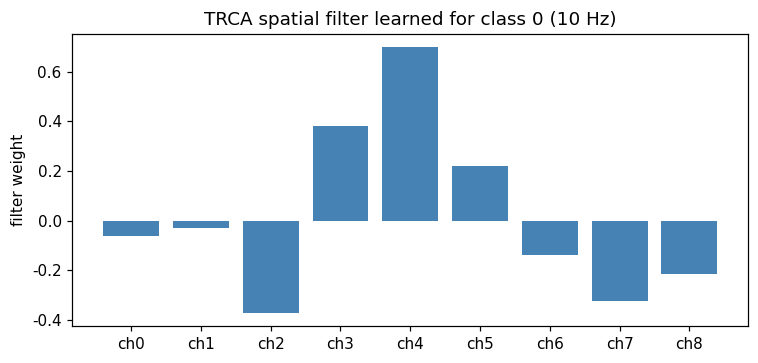

单通道 ch0 的 trial 间平均相关 : 0.266
TRCA 投影后 trial 间平均相关   : 0.910


In [4]:
# 学习一个类别的 TRCA 滤波器，并比较投影前后的试次间一致性

trials, labels, freqs = make_ssvep(noise=0.8, n_trials=8)
x0 = trials[labels == 0]                 # 类 0 的 8 个 trial
w0 = my_trca_filter(x0)

plt.figure(figsize=(7, 3.4))
plt.bar(range(9), w0, color='steelblue')
plt.xticks(range(9), [f'ch{i}' for i in range(9)])
plt.ylabel('filter weight')
plt.title('TRCA spatial filter learned for class 0 (10 Hz)')
plt.tight_layout(); plt.show()

# 滤波后 trial 间一致性应明显高于任意单个原始通道
def mean_intertrial_corr(sigs):
    J = sigs.shape[0]; rs = []
    for i in range(J):
        for j in range(i+1, J):
            rs.append(np.corrcoef(sigs[i], sigs[j])[0, 1])
    return np.mean(rs)
proj = np.einsum('jct,c->jt', x0, w0)
print('单通道 ch0 的 trial 间平均相关 : %.3f' % mean_intertrial_corr(x0[:, 0, :]))
print('TRCA 投影后 trial 间平均相关   : %.3f' % mean_intertrial_corr(proj))

## 二、类模板与基础 TRCA 分类

对每一类：用训练片段平均得到**类模板** $\bar X_k = \frac1J\sum_j X_j$。
测试片段 $X$ 经第 $k$ 个滤波器投影后，与第 $k$ 类模板的投影做皮尔逊相关，
相关最大的类为预测结果。下面每类用前 4 个 trial 训练、后 4 个测试。

In [5]:
# 为各类别学习空间滤波器和模板，再用相关性进行基础分类

filters, templates = [], []
for k in range(8):
    xk = trials[labels == k][:4]
    filters.append(my_trca_filter(xk))
    templates.append(xk.mean(axis=0))

def predict_basic(x):
    # 对每一类：用该类滤波器投影 EEG 和类别模板，再计算两者的相关系数。
    scores = [np.corrcoef(x.T @ filters[k], templates[k].T @ filters[k])[0, 1]
              for k in range(8)]
    # 得分最高的模板最像当前 EEG，因此返回它的类别编号。
    return int(np.argmax(scores))

correct, total = 0, 0
# 按类别分别取前 4 段训练、后 4 段测试，避免类别缺失。
for k in range(8):
    for x in trials[labels == k][4:]:
        correct += (predict_basic(x) == k); total += 1
print('基础 TRCA 正确率 = %.1f %%' % (100*correct/total))

基础 TRCA 正确率 = 100.0 %


## 三、ensemble TRCA

基础 TRCA 每类只用自己的一个滤波器。ensemble 策略（Nakanishi 2017）把**全部
类**的滤波器拼成滤波器组 $W=[w_1,\ldots,w_K]$，测试片段与每个类模板都经
$W$ 投影成 $(T\times K)$ 的信号再整体做相关，相当于同时比较所有任务相关成分，
准确率通常更高。工程中由 `TRCAClassifier(ensemble=True)` 实现。

In [6]:
# 划分训练与测试试次，评估集成 TRCA 分类器

from ssvep import TRCAClassifier
train_x, train_y, test_x, test_y = [], [], [], []
for k in range(8):
    xk = trials[labels == k]
    train_x.append(xk[:4]);  train_y += [k]*4
    test_x.append(xk[4:]);   test_y += [k]*4
train_x, train_y = np.vstack(train_x), np.array(train_y)
test_x, test_y = np.vstack(test_x), np.array(test_y)

trca = TRCAClassifier(n_classes=8, ensemble=True).fit(train_x, train_y)
pred = trca.predict_batch(test_x)
print('ensemble TRCA 正确率 = %.1f %%' % ((pred == test_y).mean()*100))

ensemble TRCA 正确率 = 100.0 %


## 四、留一 block 交叉验证

真实数据通常按 block（轮次）采集（如清华 Benchmark 每类 6 个 block）。
严谨的评估方式是**留一 block**：每次用其余 block 训练、留出的 block 测试，
轮换后平均。这里把每类 8 个 trial 当作 8 个 block。

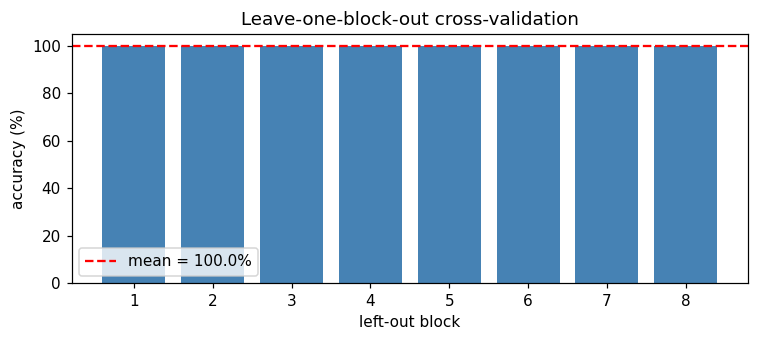

各折正确率: [100. 100. 100. 100. 100. 100. 100. 100.]


In [7]:
# 按数据块执行留一交叉验证，评估集成 TRCA 的准确率

n_per = 8
x_by_class = trials.reshape(8, n_per, 9, trials.shape[-1])   # [class, block, ch, T]
accs = []
for b in range(n_per):
    tr_blocks = [i for i in range(n_per) if i != b]
    trX = np.concatenate([x_by_class[:, i] for i in tr_blocks], axis=0)
    trY = np.tile(np.arange(8), n_per-1)
    teX = x_by_class[:, b]; teY = np.arange(8)
    model = TRCAClassifier(n_classes=8, ensemble=True).fit(trX, trY)
    accs.append((model.predict_batch(teX) == teY).mean()*100)
plt.figure(figsize=(7, 3.2))
plt.bar(range(1, n_per+1), accs, color='steelblue')
plt.axhline(np.mean(accs), color='red', ls='--',
            label='mean = %.1f%%' % np.mean(accs))
plt.xlabel('left-out block'); plt.ylabel('accuracy (%)'); plt.legend()
plt.title('Leave-one-block-out cross-validation')
plt.tight_layout(); plt.show()
print('各折正确率:', np.round(accs, 1))

## 五、训练片段数量的影响

TRCA 是监督方法，训练 trial 越多，滤波器和模板越稳定。对比不同训练量下的
ensemble TRCA，并画出 FBCCA（无需训练）作为水平参照。

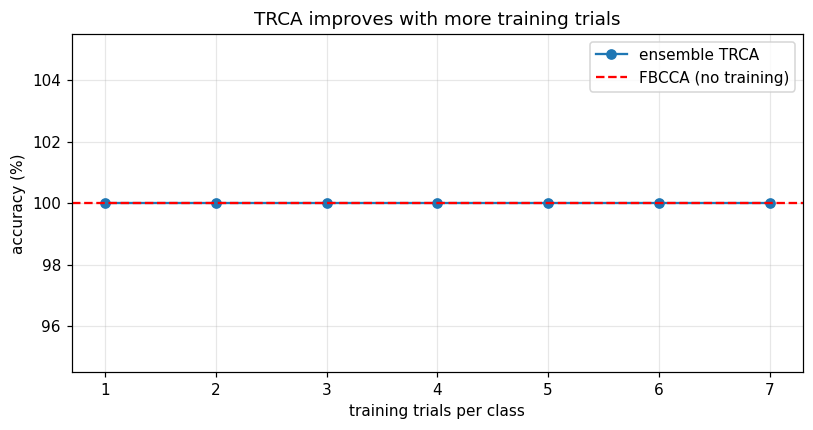

In [8]:
# 比较 TRCA 随训练试次数变化的表现与无需训练的 FBCCA 基线

from ssvep import FBCCAClassifier
fb_acc = (FBCCAClassifier(freqs, 250).predict_batch(trials) == labels).mean()*100
trca_accs = []
for n_tr in range(1, 8):
    trX = np.concatenate([x_by_class[:, i] for i in range(n_tr)], axis=0)
    trY = np.tile(np.arange(8), n_tr)
    te_blocks = [i for i in range(n_tr, n_per)]
    teX = np.concatenate([x_by_class[:, i] for i in te_blocks], axis=0)
    teY = np.tile(np.arange(8), len(te_blocks))
    m = TRCAClassifier(8, ensemble=True).fit(trX, trY)
    trca_accs.append((m.predict_batch(teX) == teY).mean()*100)
plt.figure(figsize=(7.5, 3.8))
plt.plot(range(1, 8), trca_accs, 'o-', label='ensemble TRCA')
plt.axhline(fb_acc, color='red', ls='--', label='FBCCA (no training)')
plt.xlabel('training trials per class'); plt.ylabel('accuracy (%)')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.title('TRCA improves with more training trials')
plt.show()

## 小结

- TRCA 通过最大化同类 trial 间协方差（$Q^{-1}S$ 的主特征向量）学习空间滤波器，
  把淹没在噪声里的任务相关成分提取出来。
- **ensemble TRCA** 拼接全部类滤波器后与类模板比相关，是传统方法的强基线。
- 必须有**同被试、带标签**的训练片段，且训练量越大越稳；评估应使用留一 block 交叉验证。
- 比赛策略：官方若提供带标签训练/校准数据，TRCA 往往是主力；
  若没有标签，则用 FBCCA 保底。深度学习方法见下一笔记的综合对比。